### Carregando bibliotecas e dados

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
#pd.set_option('display.max_rows', None)
#pd.set_option('display.max_columns', None)

pd.reset_option('display.max_rows')
pd.reset_option('display.max_columns')

In [43]:
df = pd.read_csv("data.csv")

C:\Users\Gabriel\AppData\Local\Temp\ipykernel_21400\3477112522.py:1: DtypeWarning: Columns (5,6,7,8,10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data.csv")


In [44]:
df_soc = pd.read_csv("societies.csv")[["ID", "Name"]].iloc[:339].copy()
df_soc

,ID,Name
0,B72,!Kung
1,B296,Kuskowagmut
2,B322,Syilx
3,B335,Round Lake Ojibwa
4,B339,North Albany Ojibwa
...,...,...
334,B215,Spring Valley Shoshoni
335,B224,Antelope Valley Shoshoni
336,B272,Chehalis
337,B293,Gitxsan


In [45]:
df_B009 = df[df["Var_ID"] == "B009"].copy().reset_index(drop=True)
df_B009.drop(columns=["ID", "Code_ID", "Source", "source_coded_data", "admin_comment"], inplace=True)

df_B021 = df[(df["Var_ID"] == "B021") & (df["Value"].notna())].copy().reset_index(drop=True)
df_B021.drop(columns=["ID", "Code_ID", "Source", "source_coded_data", "admin_comment"], inplace=True)

**Obs:** \
B009 se refere ao *nomadismo* ou *sedentarismo* da sociedade \
B021 se refere à *idade média* ao casar das mulheres

In [46]:
df_B009

,Soc_ID,Var_ID,Value,Comment,sub_case,year
0,B1,B009,Mobile,NaN,NaN,1970
1,B10,B009,Mobile,NaN,NaN,1900
2,B100,B009,Mobile,NaN,NaN,NaN
3,B101,B009,Mobile,NaN,NaN,1934
4,B102,B009,Mobile,NaN,NaN,1909
...,...,...,...,...,...,...
334,B95,B009,Mobile,NaN,NaN,1920
335,B96,B009,Mobile,NaN,NaN,1880
336,B97,B009,Mobile,NaN,NaN,1930
337,B98,B009,Mobile,"Changed to ""1"" based on Binford (2001:279): ""T...",NaN,1926


In [47]:
df_B021

,Soc_ID,Var_ID,Value,Comment,sub_case,year
0,B10,B021,14,NaN,NaN,1900
1,B100,B021,11,NaN,NaN,NaN
2,B101,B021,13,NaN,NaN,1934
3,B103,B021,14,NaN,NaN,1928
4,B105,B021,10,NaN,NaN,1900
...,...,...,...,...,...,...
200,B95,B021,9,NaN,NaN,1920
201,B96,B021,13,NaN,refers specifically to Yalandji,1880
202,B97,B021,9,NaN,NaN,1930
203,B98,B021,13,NaN,NaN,1926


In [48]:
print(f"Valores duplicados B009: {df_B009["Soc_ID"].duplicated().sum()}")
print(f"Valores duplicados B021: {df_B021["Soc_ID"].duplicated().sum()}")

Valores duplicados B009: 0
Valores duplicados B021: 8


In [49]:
for _, row in df_B021.dropna(subset=["Comment"]).iterrows():
    print(f"Society {row['Soc_ID']}")
    print(f"Comment: {row['Comment']}\n")

Society B14
Comment: Note, for this society, Binford provided two estimates (13, 17); this entry is one of those estimates

Society B14
Comment: Note, for this society, Binford provided two estimates (13, 17); this entry is one of those estimates

Society B202
Comment: Note, for this society, Binford provided two estimates (12, 13); this entry is one of those estimates

Society B202
Comment: Note, for this society, Binford provided two estimates (12, 13); this entry is one of those estimates

Society B22
Comment: Note, first of two estimates provided by Binford for this society (16, 16)

Society B22
Comment: Note, second of two estimates provided by Binford for this society (16, 16)

Society B226
Comment: Note, for this society, Binford provided two estimates (13.5, 15); this entry is one of those estimates

Society B226
Comment: Note, for this society, Binford provided two estimates (13.5, 15); this entry is one of those estimates

Society B243
Comment: Note: estimate is said to be fo

#### Lidando com sociedades com valores duplicados

In [50]:
df_B021["Value"] = pd.to_numeric(df_B021["Value"])
df_B021_corrigido = df_B021.groupby(["Soc_ID", "sub_case"], dropna=False, as_index=False)["Value"].mean()
df_B021_corrigido

,Soc_ID,sub_case,Value
0,B10,NaN,14.0
1,B100,NaN,11.0
2,B101,NaN,13.0
3,B103,NaN,14.0
4,B105,NaN,10.0
...,...,...,...
194,B95,NaN,9.0
195,B96,refers specifically to Yalandji,13.0
196,B97,NaN,9.0
197,B98,NaN,13.0


In [51]:
print(f"Valores duplicados B021: {df_B021_corrigido["Soc_ID"].duplicated().sum()}")

Valores duplicados B021: 2


### Criando conjunto de dados para teste

In [52]:
### Juntando as variáveis
df_teste = pd.merge(
    df_B009[["Soc_ID", "Value"]],
    df_B021_corrigido[["Soc_ID", "sub_case", "Value"]],
    on="Soc_ID",
    how="inner",
    suffixes=("_B009", "_B021"),
    validate="one_to_many"
)

In [53]:
### Nomeando as sociedades e as variáveis
df_teste = df_teste.merge(
    df_soc,
    left_on="Soc_ID",
    right_on="ID",
    how="left",
)
df_teste = df_teste[["Name", "sub_case", "Value_B009", "Value_B021"]]
df_teste.columns = ["Society", "sub_case", "Mobility", "Avg age of marriage of women"]
df_teste

,Society,sub_case,Mobility,Avg age of marriage of women
0,Vedda,NaN,Mobile,14.0
1,Worrorra,NaN,Mobile,11.0
2,Kija,NaN,Mobile,13.0
3,Kaiadilt,NaN,Mobile,14.0
4,Mamu,NaN,Mobile,10.0
...,...,...,...,...
194,Tiwi,NaN,Mobile,9.0
195,Kuku (Yalanji),refers specifically to Yalandji,Mobile,13.0
196,Anindilyagwa,NaN,Mobile,9.0
197,Walmbaria,NaN,Mobile,13.0


### Análise descritiva

#### Estatísticas descritivas das variáveis

In [54]:
df_teste.head()

,Society,sub_case,Mobility,Avg age of marriage of women
0,Vedda,NaN,Mobile,14.0
1,Worrorra,NaN,Mobile,11.0
2,Kija,NaN,Mobile,13.0
3,Kaiadilt,NaN,Mobile,14.0
4,Mamu,NaN,Mobile,10.0


In [55]:
# Missing values
print(df_teste.isnull().sum())

Society                           0
sub_case                        194
Mobility                          0
Avg age of marriage of women      0
dtype: int64


In [56]:
print(df_teste["Avg age of marriage of women"].describe())

count    199.000000
mean      14.132915
std        2.486739
min        5.000000
25%       13.000000
50%       14.000000
75%       15.500000
max       22.000000
Name: Avg age of marriage of women, dtype: float64


In [57]:
print(df_teste["Mobility"].describe())

count        199
unique         2
top       Mobile
freq         141
Name: Mobility, dtype: object


In [69]:
print(df_teste.loc[df_teste["Mobility"] == "Sedentary", "Avg age of marriage of women"].describe())

count    58.000000
mean     14.665517
std       2.379632
min       5.000000
25%      13.625000
50%      14.500000
75%      15.875000
max      20.000000
Name: Avg age of marriage of women, dtype: float64


In [70]:
print(df_teste.loc[df_teste["Mobility"] == "Mobile", "Avg age of marriage of women"].describe())

count    141.000000
mean      13.913830
std        2.504875
min        6.500000
25%       13.000000
50%       14.000000
75%       15.500000
max       22.000000
Name: Avg age of marriage of women, dtype: float64


#### Gráficos das variáveis

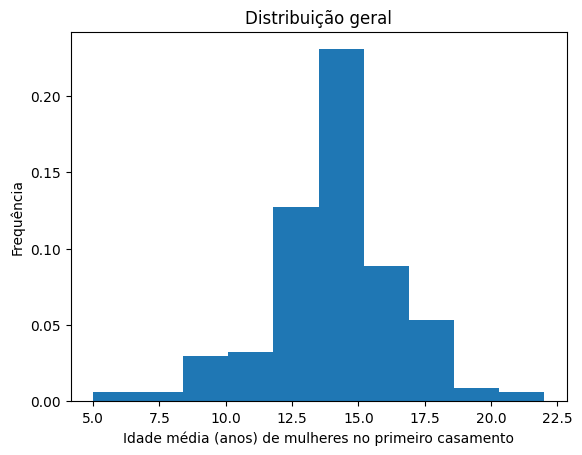

In [ ]:
### Histograma geral

plt.figure()
plt.hist(df_teste["Avg age of marriage of women"], density=True)
plt.xlabel("Idade média (anos) de mulheres no primeiro casamento")
plt.ylabel("Frequência")
plt.title("Distribuição geral")
plt.show()

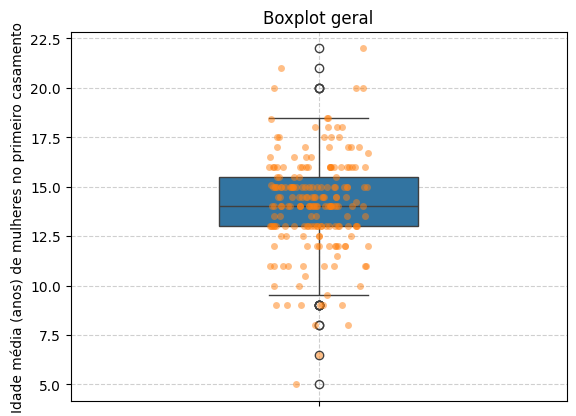

In [ ]:
### Boxplot geral

plt.figure()
sns.boxplot(df_teste["Avg age of marriage of women"], width=0.4)
sns.stripplot(df_teste["Avg age of marriage of women"], alpha=0.5)
plt.title("Boxplot geral")
plt.ylabel('Idade média (anos) de mulheres no primeiro casamento')
plt.grid(linestyle='--', alpha=0.6)
plt.show()

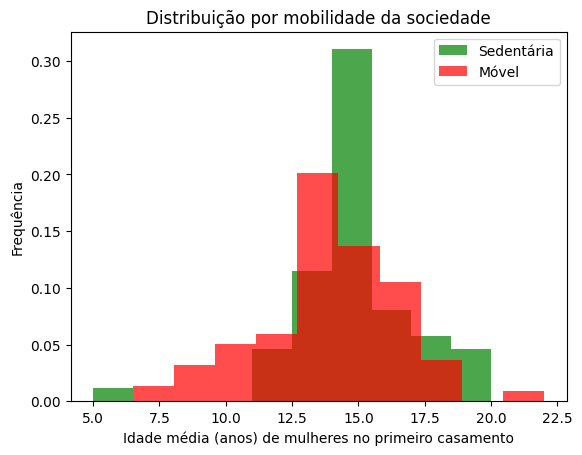

In [ ]:
### histogramas por mobilidade da sociedade

plt.figure()

plt.hist(df_teste.loc[df_teste["Mobility"] == "Sedentary", "Avg age of marriage of women"],
         density=True,
         color="green",
         alpha=0.7,
         label="Sedentária"
         )
plt.hist(df_teste.loc[df_teste["Mobility"] == "Mobile", "Avg age of marriage of women"],
         density=True,
         color="red",
         alpha=0.7,
         label="Móvel"
         )

plt.xlabel("Idade média (anos) de mulheres no primeiro casamento")
plt.ylabel("Frequência")
plt.title("Distribuição por mobilidade da sociedade")
plt.legend()
plt.show()

C:\Users\Gabriel\AppData\Local\Temp\ipykernel_21400\1615900517.py:14: UserWarning: 
The palette list has fewer values (1) than needed (2) and will cycle, which may produce an uninterpretable plot.
  sns.stripplot(


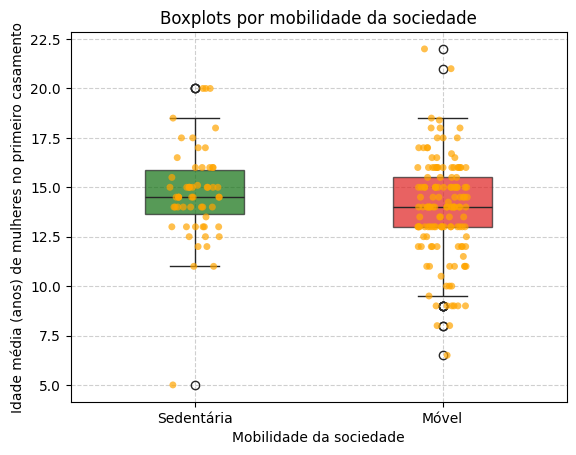

In [ ]:
### Boxplot por mobilidade da sociedade

plt.figure()

sns.boxplot(
            data=df_teste,
            x="Mobility",
            y="Avg age of marriage of women",
            order=["Sedentary", "Mobile"],
            hue="Mobility",
            palette=["red", "green"],
            width=0.4,
            boxprops={"alpha": 0.7}
)

sns.stripplot(
            data=df_teste,
            x="Mobility",
            y="Avg age of marriage of women",
            order=["Sedentary", "Mobile"],
            hue="Mobility",
            palette=["orange"],
            alpha=0.7
)

plt.title("Boxplots por mobilidade da sociedade")
plt.xticks(
    ticks=[0, 1],
    labels=["Sedentária", "Móvel"]
)
plt.xlabel("Mobilidade da sociedade")
plt.ylabel("Idade média (anos) de mulheres no primeiro casamento")
plt.grid(linestyle='--', alpha=0.6)
plt.show()